## 1. Wisdom of the Crowd:

In 1906, Francis Galton studied a weight-guessing contest for an ox at a country fair. Hundreds of people guessed, and almost none were experts. Yet the average of all the guesses landed within about 1% of the true weight, which was closer than most individual guesses, including those of the livestock experts.

Ensemble learning applies this idea to models. Individual guesses are noisy, but their errors point in different directions and partly cancel when you aggregate. The effect needs a few conditions:

- **Diversity:** the guessers must make different mistakes. A crowd that all copies one answer adds nothing.
- **Independence:** one guess shouldn't depend on another.
- **Better than random:** each guesser must be right more often than not.
- **Aggregation:** there must be a rule that merges the guesses into one answer (vote, average, weighted sum).

The classic mathematical version is **Condorcet's jury theorem**. Suppose each classifier is right 60% of the time and their errors are independent. Then the accuracy of the majority vote is:

| Number of voters | Majority-vote accuracy |
|---|---|
| 1 | 60.0% |
| 3 | 64.8% |
| 11 | 75.3% |
| 21 | 82.6% |
| 101 | 97.9% |

Real models never have fully independent errors, so you won't reach those numbers. They show why diversity matters.

---

## 2. Core Idea:

An ensemble trains several **base learners** and combines their predictions into one final prediction. The base learners are often weak or unstable on their own, such as shallow or deep decision trees. The ensemble is the strong learner built from them.

Combination rules:

- **Classification:** hard voting (majority class) or soft voting (average the predicted probabilities, then pick the highest).
- **Regression:** average the predictions, or take a weighted average.
- **Learned combination:** a second model takes the base predictions as input (stacking).

A model's expected error splits into **bias² + variance + irreducible noise**. Ensembles can't remove the noise, but they attack the other two parts: some methods mainly cut variance, others mainly cut bias. That distinction drives the types below.

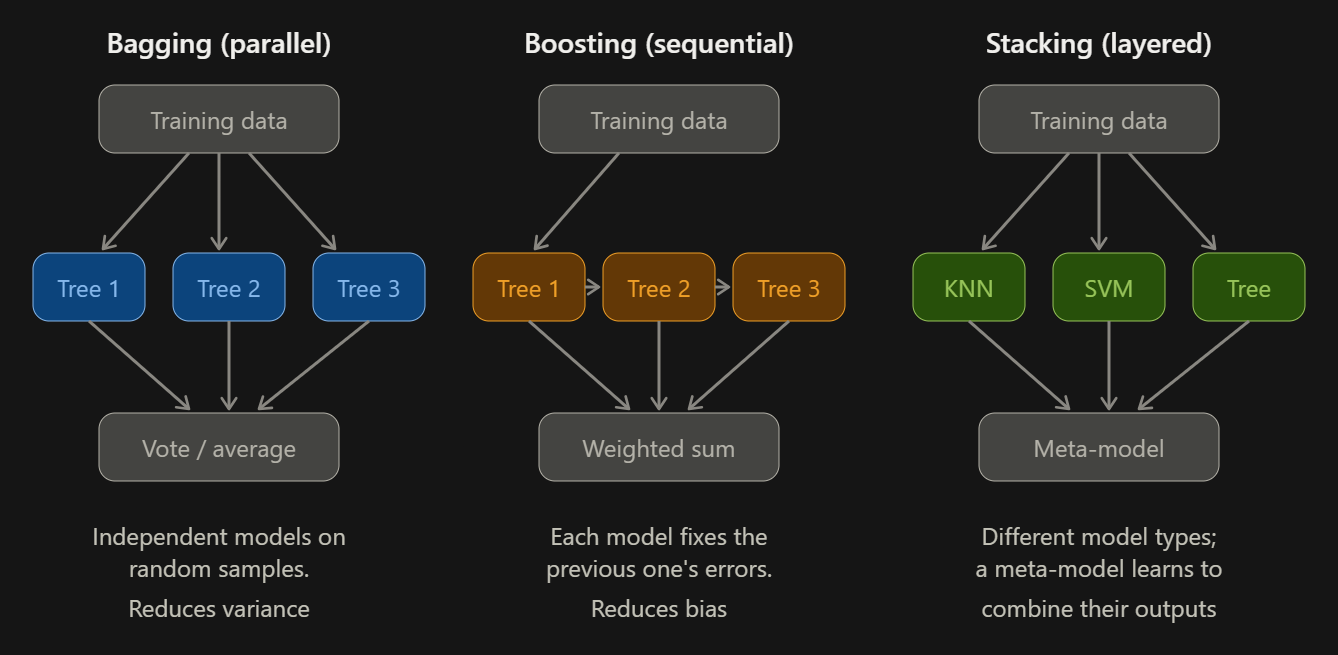

---

## 3. Types of Ensemble Learning:

**Bagging (Bootstrap Aggregating)** trains many models in parallel, each on a different **bootstrap sample**: a random sample of the training set drawn with replacement. A bootstrap sample contains about 63.2% of the unique rows, because the chance a given row is never picked is (1 − 1/n)ⁿ ≈ 0.368. The remaining ~36.8% are **out-of-bag (OOB)** rows, which give a free validation score without a separate validation set. Predictions are combined by voting or averaging.

- **Random Forest** is bagged decision trees plus a second source of randomness: each split only considers a random subset of features (√p is the usual choice for classification). This decorrelates the trees, which makes the averaging work better.
- **Extra Trees** goes further by also picking split thresholds at random.
- Bagging works best on **high-variance** learners such as deep, unpruned trees.

**Boosting** trains models one after another, and each new model focuses on what the previous ones got wrong.

- **AdaBoost** reweights the training points. After each round, misclassified points get more weight. Each model gets a say proportional to its accuracy: α = ½ ln((1 − ε)/ε), where ε is its weighted error. The final prediction is the sign of the weighted sum.
- **Gradient Boosting** fits each new tree to the **residuals** (more precisely, the negative gradient of the loss) of the current ensemble: F_m = F_(m−1) + η · h_m, where η is the learning rate. For squared error, the residual is just y − F(x).
- **XGBoost, LightGBM and CatBoost** are fast, regularized implementations of gradient boosting, and they dominate tabular-data competitions.
- Boosting uses **weak** learners (shallow trees, often depth 1 to 3) and mainly reduces **bias**. It is sensitive to noisy labels and needs tuning of `learning_rate`, `n_estimators` and tree depth.

**Stacking** combines different kinds of models (say KNN, SVM and a tree). Their predictions become the input features of a **meta-model**, usually something simple like logistic regression. The key rule: train the meta-model on **out-of-fold** predictions (from cross-validation), otherwise it sees predictions on data the base models already memorized, which leaks information and overfits.

**Voting** is the simplest version of this idea: several different models vote, with no learned combiner. Hard voting counts class labels; soft voting averages probabilities and usually does better when the models give calibrated probabilities.

| | Bagging | Boosting | Stacking |
|---|---|---|---|
| Training | Parallel, independent | Sequential, dependent | Two levels |
| Main effect | Reduces variance | Reduces bias | Exploits model diversity |
| Base learners | Strong, high-variance (deep trees) | Weak (shallow trees) | Different algorithms |
| Overfitting risk | Low | Higher (noise, too many rounds) | Moderate (leakage if done wrong) |
| Parallelizable | Yes | Not across rounds | Base level yes |
| Example | Random Forest | AdaBoost, XGBoost | `StackingClassifier` |

---

## 4. Why It Works:

**Variance reduction (bagging).** Say each of n models has prediction variance σ², and any two models' predictions have correlation ρ. The variance of their average is:

**Var = ρσ² + (1 − ρ)σ² / n**

As n grows, the second term vanishes, but the first term stays. So the floor on your error depends on how **correlated** the models are, which is why random forests deliberately decorrelate their trees with feature subsampling. If ρ = 1 (identical models), averaging does nothing. If ρ = 0, variance falls as σ²/n.

**Bias reduction (boosting).** A single stump is a very crude model. Adding many stumps, each fitted to the remaining error, builds a flexible function step by step. The ensemble can represent shapes that no single weak learner could.

**Representational power.** The average or vote of simple models can represent functions outside any single model's hypothesis space. A diagonal boundary, for instance, is impossible for one axis-aligned tree but easy for a combination of many.

**Escaping bad luck.** Training is sensitive to initialization and data order, so one run can land in a poor solution. Averaging many runs reduces the risk that you depend on one unlucky run.

**Diversity is what you need to create.** Common ways to get it:

- different data samples (bagging)
- different feature subsets (random forest)
- different algorithms (stacking and voting)
- different hyperparameters or random seeds
- focusing on different errors (boosting)

---

## 5. Benefits:

- **Higher accuracy** than most single models on tabular data. Ensembles win a large share of tabular machine-learning competitions.
- **Lower variance and less overfitting**, especially with bagging, since individual trees' quirks average out.
- **Stability:** small changes in the training data change the ensemble far less than they change one tree.
- **Robustness to noise and outliers**, since a few bad points influence only some of the models.
- **Built-in extras:** OOB error estimates and feature importances come for free with random forests.
- **Flexible:** any base learner can be used, and bagging parallelizes easily.

---

## 6. When to Use (and When Not To):

**Use ensembles when:**

- a single model is **unstable** or overfits, such as a deep decision tree that gives very different trees on slightly different data (a variance problem → bagging or random forest)
- a simple model **underfits** and you need more capacity (a bias problem → boosting)
- accuracy matters more than interpretability, which is the usual case for tabular prediction
- you have several decent but different models and want to combine them (voting or stacking)
- the data is noisy or has many features

**Think twice when:**

- you need a **fully interpretable** model: a forest of 500 trees can't be read like one tree (feature importances help, but only partly)
- **latency or memory** is tight, since you must run and store many models
- the dataset is **tiny**, where an ensemble adds complexity without much gain
- your base models make **highly correlated errors**, because averaging near-identical models gains almost nothing
- the labels are very noisy and you're using boosting, which may chase the noise (consider more regularization or early stopping)

**Practical workflow:** start with a single decision tree as a baseline, then a Random Forest (hard to get badly wrong). If you need more accuracy, try gradient boosting with a small learning rate and early stopping. Reach for stacking last, since it's the most complex and gains the least when your base models are similar.

---

## Scikit-learn map

- Bagging: `BaggingClassifier`, `RandomForestClassifier`, `ExtraTreesClassifier`
- Boosting: `AdaBoostClassifier`, `GradientBoostingClassifier`, `HistGradientBoostingClassifier` (plus the separate `xgboost`, `lightgbm`, `catboost` packages)
- Combining: `VotingClassifier`, `StackingClassifier`

Each has a `...Regressor` version for regression.

---